# Final result

Global matching, the test evaluation and the group sizes of each run.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
final = pd.read_csv("results/final.csv")
final[["run", "pair", "matcher", "split", "P", "R", "F1", "corr"]]

,run,pair,matcher,split,P,R,F1,corr
0,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.944,0.944,0.944,17597
1,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.970,0.915,0.942,13316
2,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.977,0.908,0.942,13268
3,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.961,0.873,0.915,13367
4,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,test,0.991,0.903,0.945,13316
5,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.965,0.914,0.939,5878
6,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.993,0.882,0.934,4433
7,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.993,0.882,0.934,4426
8,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,validation,0.978,0.882,0.927,4449
9,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,test,0.992,0.874,0.929,4433


## Global matching (validation labels)

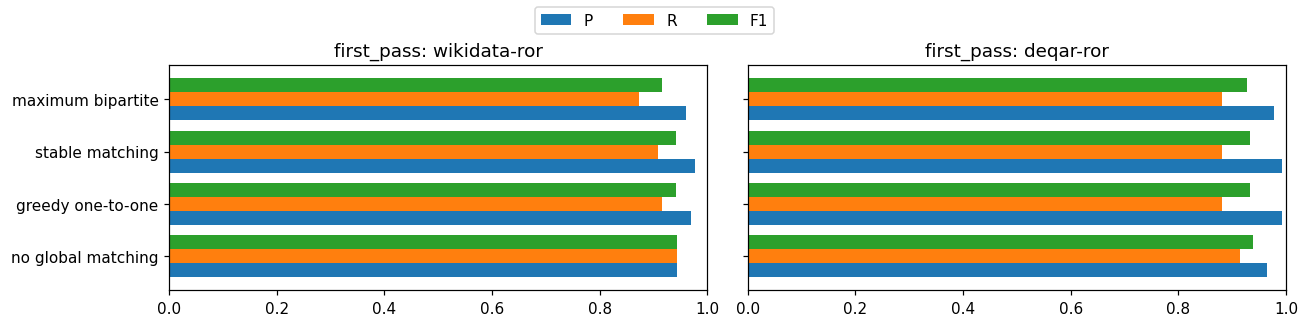

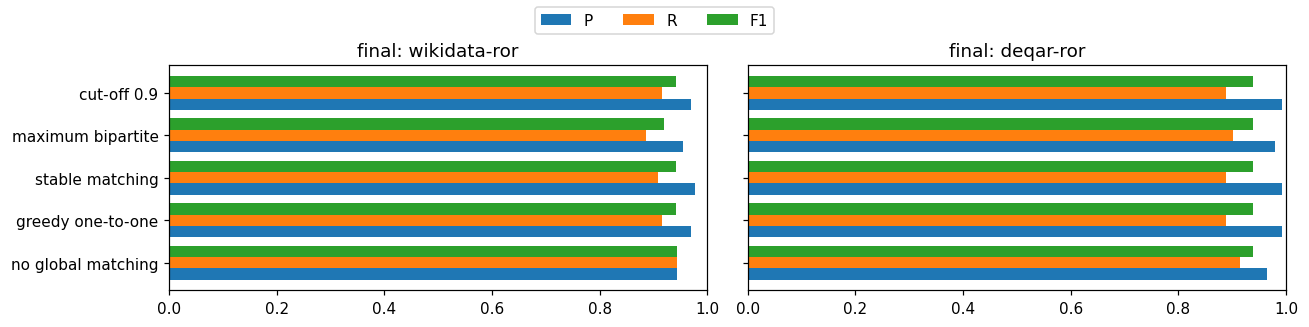

In [3]:
val = final[final["split"] == "validation"].copy()
val["global"] = val["matcher"].str.split(" \\+ ").str[-1]
for run in ["first_pass", "final"]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = val[(val["run"] == run) & (val["pair"] == pair)].set_index("global")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"{run}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## Test result of each run

The test labels are only used once per run, for the final choice.

,run,pair,matcher,P,R,F1,corr
4,first_pass,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.991,0.903,0.945,13316
9,first_pass,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.992,0.874,0.929,4433
14,final,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.991,0.903,0.945,12499
16,final,wikidata-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.991,0.903,0.945,12499
21,final,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.992,0.881,0.933,4238
23,final,deqar-ror,fine-tuned multilingual MiniLM cross-encoder +...,0.992,0.881,0.933,4238


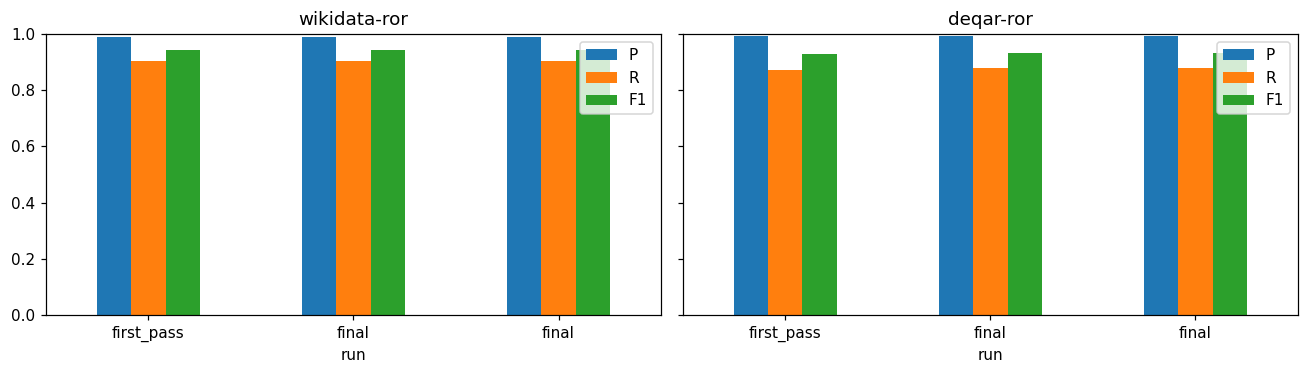

In [4]:
test = final[final["split"] == "test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, pair in zip(axes, PAIRS):
    test[test["pair"] == pair].set_index("run")[["P", "R", "F1"]].plot.bar(ax=ax, rot=0)
    ax.set_ylim(0, 1)
    ax.set_title(pair)
plt.tight_layout()
test[["run", "pair", "matcher", "P", "R", "F1", "corr"]]

## Group size distribution

With duplicate-free sources a group should have at most 3 records (one per source).

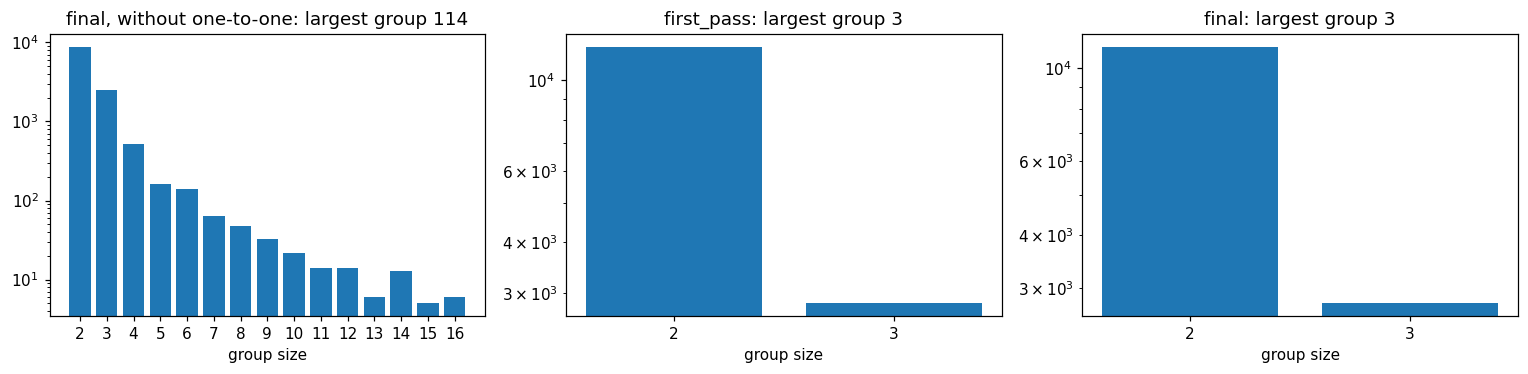

In [5]:
from pathlib import Path

GROUPS = {"final, without one-to-one": "group_sizes_final_without_one_to_one.csv",
          "first_pass": "group_sizes_first_pass.csv", "final": "group_sizes_final.csv"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (title, file) in zip(axes, GROUPS.items()):
    path = Path("results") / file
    if not path.exists():
        continue
    sizes = pd.read_csv(path)
    ax.bar(sizes["cluster_size"].astype(str).head(15), sizes["frequency"].head(15))
    ax.set_yscale("log")
    ax.set_title(f"{title}: largest group {sizes['cluster_size'].max():,}")
    ax.set_xlabel("group size")
plt.tight_layout()